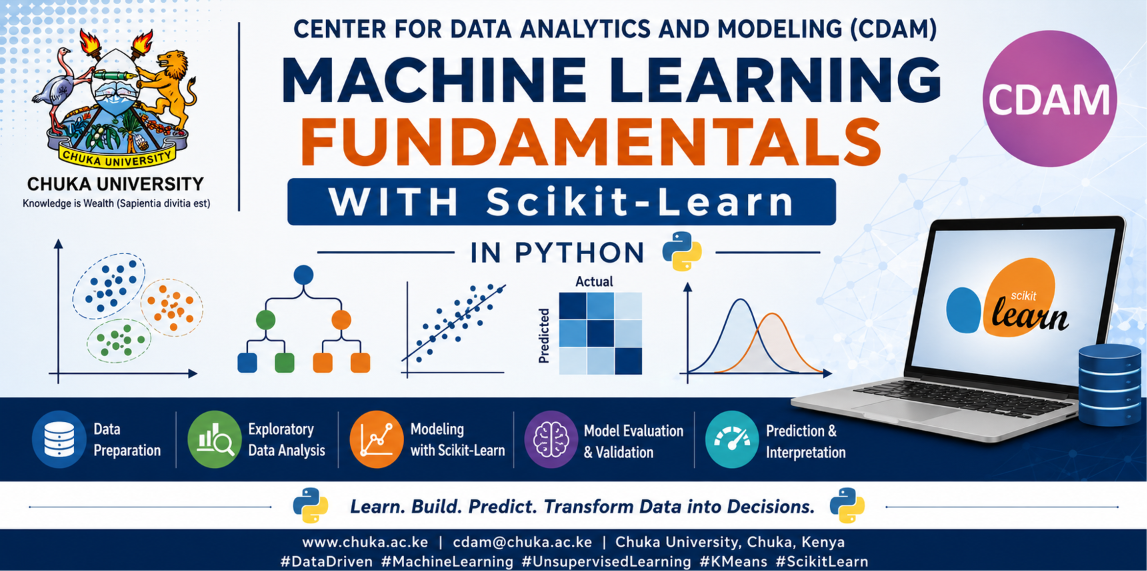

## **SESSION 4: MACHINE LEARNING FUNDAMENTALS WOTH SCIKIT-LEARN**
> **Objective: End-to-end ML workflow using Scikit-Learn on the Heart Disease dataset**

In [3]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import warnings
warnings.filterwarnings('ignore')

# Scikit-Learn imports
from sklearn.model_selection import train_test_split, cross_val_score
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.impute import SimpleImputer
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.ensemble import RandomForestRegressor
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_squared_error, mean_absolute_error, r2_score

## **PART 1: MACHINE LEARNING FUNDAMENTALS & CONCEPTS**
### **Introduction to Machine Learning**
   - ML is the science of building systems that automatically learn and improve 
     from experience (data) without being explicitly programmed.

### **Supervised vs. Unsupervised Learning**
   - SUPERVISED LEARNING: The algorithm learns from labeled training data. 
     It maps inputs (X) to known outputs (y). 
     * Regression: Predicting a continuous number (e.g., House Price, MaxHR).
     * Classification: Predicting a category (e.g., Spam vs. Not Spam).
   - UNSUPERVISED LEARNING: The algorithm finds hidden patterns in unlabeled data.
     * Clustering: Grouping similar data points (e.g., Customer segmentation).
     * Dimensionality Reduction: Compressing data (e.g., PCA).

### **The Scikit-Learn Workflow**
   - Estimators: Any object that learns from data (e.g., RandomForestRegressor). 
                 They use the .fit() method to learn parameters.
   - Transformers: Objects that preprocess data (e.g., StandardScaler). 
                   They use .fit(), .transform(), and .fit_transform().
   - Pipelines: Chain multiple transformers and a final estimator together. 
                This prevents data leakage and makes code clean/reproducible

## **PART 2: DATA LOADING & EXPLORATION**
*   **Data Ingestion:** Using `pandas.read_csv()` to load data. Passing `na_values=['NA']` ensures that string representations of missing data are correctly recognized as actual `NaN` (Not a Number) values by pandas.
*   **Initial Exploration (EDA):**
    *   `.shape`: Tells us the dimensions (Rows/Samples × Columns/Features). Here, 303 patients and 15 attributes.
    *   `.head()`: A quick sanity check to ensure data loaded correctly and to see data types (e.g., noticing `ChestPain` is text, while `Age` is numeric).
    *   `.isnull().sum()`: Crucial for identifying missing data. In this dataset, `Ca` and `Thal` have missing values, which must be handled before feeding data into a math-based ML model.

In [4]:
print("="*80)
print("PART 2: DATA LOADING & PREPARATION")
print("="*80)

# Load the dataset. Note: The dataset uses the string 'NA' for missing values.
df = pd.read_csv('Heart.csv', na_values=['NA'])

print(f"Dataset Shape: {df.shape}")
print(f"\nFirst 5 Rows:")
print(df.head())

# Check for missing values
print(f"\nMissing Values per Column:")
print(df.isnull().sum()[df.isnull().sum() > 0])

PART 2: DATA LOADING & PREPARATION
Dataset Shape: (303, 15)

First 5 Rows:
   Age  Sex     ChestPain  RestBP  Chol  Fbs  RestECG  MaxHR  ExAng  Oldpeak  \
0   63    1       typical     145   233    1        2    150      0      2.3   
1   67    1  asymptomatic     160   286    0        2    108      1      1.5   
2   67    1  asymptomatic     120   229    0        2    129      1      2.6   
3   37    1    nonanginal     130   250    0        0    187      0      3.5   
4   41    0    nontypical     130   204    0        2    172      0      1.4   

   Slope   Ca        Thal  AHD  HD  
0      3  0.0       fixed   No   0  
1      2  3.0      normal  Yes   1  
2      2  2.0  reversable  Yes   1  
3      3  0.0      normal   No   0  
4      1  0.0      normal   No   0  

Missing Values per Column:
Ca      4
Thal    2
dtype: int64


## **PART 3: DEFINING FEATURES (X) AND TARGET (y)**
*   **X (Features) vs. y (Target):** ML models require inputs (`X`) and an output to predict (`y`). 
*   **Avoiding Data Leakage:** *Data leakage* occurs when information from outside the training dataset (like the final answer) is used to create the model. Here, the dataset has a binary column `HD` (Heart Disease: 0 or 1). Since our goal is *Regression* (predicting the continuous `MaxHR`), we must drop `HD`. If we kept it, the model might cheat by using the disease status to perfectly guess the heart rate, resulting in a model that fails in the real world.
*   **Feature Typing:** We separate columns into `numeric_features` and `categorical_features`. This is necessary because ML models require different mathematical treatments for numbers vs. text categories.

In [6]:
print("\n" + "="*80)
print("PART 3: DEFINING FEATURES AND TARGET FOR REGRESSION")
print("="*80)
print("Target Variable: 'MaxHR' (Maximum Heart Rate) - A continuous numeric outcome.")
print("We will drop 'hd' (the binary classification target) to avoid data leakage.")

target = 'MaxHR'
X = df.drop(columns=[target, 'HD']) 
y = df[target]

# Separate features by data type for preprocessing
numeric_features = ['Age', 'Sex', 'RestBP', 'Chol', 'Fbs', 'RestECG', 'ExAng', 'Oldpeak', 'Slope', 'Ca']
categorical_features = ['ChestPain', 'Thal', 'AHD']

print(f"Numeric Features ({len(numeric_features)}): {numeric_features}")
print(f"Categorical Features ({len(categorical_features)}): {categorical_features}")


PART 3: DEFINING FEATURES AND TARGET FOR REGRESSION
Target Variable: 'MaxHR' (Maximum Heart Rate) - A continuous numeric outcome.
We will drop 'hd' (the binary classification target) to avoid data leakage.
Numeric Features (10): ['Age', 'Sex', 'RestBP', 'Chol', 'Fbs', 'RestECG', 'ExAng', 'Oldpeak', 'Slope', 'Ca']
Categorical Features (3): ['ChestPain', 'Thal', 'AHD']


## **PART 4: DATA PREPROCESSING (Transformers)**
Real-world data is messy. Models cannot process missing values or text strings.
*   **Imputation (Handling Missing Values):**
    *   *Numeric:* We use the **Median** instead of the Mean because the median is robust to extreme outliers (e.g., one unusually high cholesterol reading won't skew the fill value).
    *   *Categorical:* We use the **Most Frequent** category (the mode) to fill in blanks.
*   **Encoding (Text to Numbers):** Models only understand math. **One-Hot Encoding** converts categories (like `ChestPain: typical, asymptomatic`) into binary (0 or 1) columns. 
*   **Feature Scaling:** **Standardization** rescales numeric features so they have a mean of 0 and a standard deviation of 1. This ensures features with large natural ranges (like `Chol` ~200-300) don't overpower features with small ranges (like `Oldpeak` ~0-5).
*   **ColumnTransformer:** A powerful Scikit-Learn tool that applies the *Numeric Pipeline* only to numeric columns, and the *Categorical Pipeline* only to text columns, combining them seamlessly.

In [7]:
print("\n" + "="*80)
print("PART 4: DATA PREPROCESSING STRATEGY")
print("="*80)
print("""
1. Handling Missing Values (Imputation):
   - Numeric: Fill missing values with the median (robust to outliers).
   - Categorical: Fill missing values with the most frequent category.
2. Encoding Categorical Variables:
   - One-Hot Encoding: Converts categories into binary (0/1) columns so 
     math-based models can understand them.
3. Feature Scaling:
   - Standardization: Transforms numeric data to have a mean of 0 and 
     standard deviation of 1. Crucial for distance-based algorithms.
""")

# Build Numeric Pipeline
numeric_transformer = Pipeline(steps=[
    ('imputer', SimpleImputer(strategy='median')),
    ('scaler', StandardScaler())
])

# Build Categorical Pipeline
categorical_transformer = Pipeline(steps=[
    ('imputer', SimpleImputer(strategy='most_frequent')),
    ('onehot', OneHotEncoder(handle_unknown='ignore'))
])

# Combine preprocessors using ColumnTransformer
preprocessor = ColumnTransformer(
    transformers=[
        ('num', numeric_transformer, numeric_features),
        ('cat', categorical_transformer, categorical_features)
    ])



PART 4: DATA PREPROCESSING STRATEGY

1. Handling Missing Values (Imputation):
   - Numeric: Fill missing values with the median (robust to outliers).
   - Categorical: Fill missing values with the most frequent category.
2. Encoding Categorical Variables:
   - One-Hot Encoding: Converts categories into binary (0/1) columns so 
     math-based models can understand them.
3. Feature Scaling:
   - Standardization: Transforms numeric data to have a mean of 0 and 
     standard deviation of 1. Crucial for distance-based algorithms.



## **PART 5: BUILDING THE SCIKIT-LEARN PIPELINE**
*   **The Pipeline Object:** Instead of manually running `.fit_transform()` on training data and `.transform()` on test data (which is prone to human error), a `Pipeline` bundles the Preprocessor and the Model (`RandomForestRegressor`) into one single object.
*   **Why use Pipelines?**
    1.  **Prevents Data Leakage:** Ensures that scaling/imputation parameters are learned *only* from the training data and then applied to the test data.
    2.  **Clean Code:** Reduces dozens of lines of preprocessing code into a single `.fit()` and `.predict()` call.
    3.  **Reproducibility:** Makes it easy to save and deploy the exact same workflow to production.

In [8]:
print("="*80)
print("PART 5: BUILDING THE ML PIPELINE")
print("="*80)
print("Combining the Preprocessor (Transformers) and the Regressor (Estimator).")

# Create the full pipeline
model_pipeline = Pipeline(steps=[
    ('preprocessor', preprocessor),
    ('regressor', RandomForestRegressor(n_estimators=100, random_state=42))
])

print("\nPipeline Structure:")
print(model_pipeline)


PART 5: BUILDING THE ML PIPELINE
Combining the Preprocessor (Transformers) and the Regressor (Estimator).

Pipeline Structure:
Pipeline(steps=[('preprocessor',
                 ColumnTransformer(transformers=[('num',
                                                  Pipeline(steps=[('imputer',
                                                                   SimpleImputer(strategy='median')),
                                                                  ('scaler',
                                                                   StandardScaler())]),
                                                  ['Age', 'Sex', 'RestBP',
                                                   'Chol', 'Fbs', 'RestECG',
                                                   'ExAng', 'Oldpeak', 'Slope',
                                                   'Ca']),
                                                 ('cat',
                                                  Pipeline(steps=[('imputer',
            

## **PART 6: TRAIN-TEST SPLIT & CROSS-VALIDATION**
*   **Train-Test Split:** We hold back 20% of the data (the Test Set) as a "final exam." The model *never* sees this data during training. This tests the model's ability to **generalize** to new, unseen patients.
*   **Cross-Validation (CV):** Instead of just training once and hoping for the best, we split the *Training Set* into 5 "folds". We train on 4 folds and test on 1, repeating this 5 times. 
    *   *Why?* It provides a much more robust and reliable estimate of model performance (Mean CV R²) and tells us how stable the model is (Standard Deviation).

In [9]:
print("\n" + "="*80)
print("PART 6: TRAIN-TEST SPLIT & CROSS-VALIDATION")
print("="*80)
print("""
- Train-Test Split: Reserves a portion of data (20%) that the model NEVER sees 
  during training. This tests how well the model generalizes to new data.
- Cross-Validation (CV): Splits the training data into 'k' folds. The model is 
  trained on k-1 folds and tested on the remaining fold, repeated k times. 
  This gives a more robust estimate of model performance.
""")

# 1. Train-Test Split
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42
)
print(f"Training set size: {X_train.shape[0]} samples")
print(f"Test set size:     {X_test.shape[0]} samples")

# 2. Cross-Validation on the Training Set
print("\nRunning 5-Fold Cross-Validation on Training Data...")
cv_scores = cross_val_score(model_pipeline, X_train, y_train, cv=5, scoring='r2')
print(f"Cross-Validation R² Scores: {np.round(cv_scores, 4)}")
print(f"Mean CV R²: {cv_scores.mean():.4f} (+/- {cv_scores.std() * 2:.4f})")



PART 6: TRAIN-TEST SPLIT & CROSS-VALIDATION

- Train-Test Split: Reserves a portion of data (20%) that the model NEVER sees 
  during training. This tests how well the model generalizes to new data.
- Cross-Validation (CV): Splits the training data into 'k' folds. The model is 
  trained on k-1 folds and tested on the remaining fold, repeated k times. 
  This gives a more robust estimate of model performance.

Training set size: 242 samples
Test set size:     61 samples

Running 5-Fold Cross-Validation on Training Data...
Cross-Validation R² Scores: [0.3275 0.392  0.3867 0.1698 0.3606]
Mean CV R²: 0.3273 (+/- 0.1640)


## **PART 7: MODEL TRAINING & EVALUATION**
**Concept Explanation:**
*   **Training & Predicting:** We call `.fit(X_train, y_train)` to learn the patterns, and `.predict(X_test)` to generate predictions for the unseen test set.
*   **Regression Metrics:**
    *   **MSE (Mean Squared Error):** Average squared difference between actual and predicted. Heavily penalizes large errors.
    *   **RMSE (Root Mean Squared Error):** The square root of MSE. *Advantage:* It is in the exact same units as the target (e.g., "beats per minute"), making it easy to interpret.
    *   **MAE (Mean Absolute Error):** Average absolute difference. Very intuitive (e.g., "On average, our predictions are off by 16.3 bpm").
    *   **R² (R-squared):** Represents the proportion of variance in the target explained by the model. Ranges from 0 to 1 (higher is better). An R² of 0.36 means the model explains ~36% of the variance in Maximum Heart Rate.

In [10]:
print("\n" + "="*80)
print("PART 7: MODEL TRAINING & EVALUATION")
print("="*80)
print("""
Model Evaluation Metrics for Regression:
- MSE (Mean Squared Error): Average squared difference between predicted and actual.
- RMSE (Root Mean Squared Error): MSE in the original units of the target.
- MAE (Mean Absolute Error): Average absolute difference (easy to interpret).
- R² (R-squared): Proportion of variance in the target explained by the model (0 to 1).
""")

# 1. Train the final model on the full training set
model_pipeline.fit(X_train, y_train)

# 2. Predict on the unseen test set
y_pred = model_pipeline.predict(X_test)

# 3. Calculate Metrics
mse = mean_squared_error(y_test, y_pred)
rmse = np.sqrt(mse)
mae = mean_absolute_error(y_test, y_pred)
r2 = r2_score(y_test, y_pred)

print("--- Final Test Set Evaluation ---")
print(f"Mean Squared Error (MSE) : {mse:.4f}")
print(f"Root Mean Squared Error  : {rmse:.4f}")
print(f"Mean Absolute Error (MAE): {mae:.4f}")
print(f"R-squared (R²)           : {r2:.4f}")


PART 7: MODEL TRAINING & EVALUATION

Model Evaluation Metrics for Regression:
- MSE (Mean Squared Error): Average squared difference between predicted and actual.
- RMSE (Root Mean Squared Error): MSE in the original units of the target.
- MAE (Mean Absolute Error): Average absolute difference (easy to interpret).
- R² (R-squared): Proportion of variance in the target explained by the model (0 to 1).

--- Final Test Set Evaluation ---
Mean Squared Error (MSE) : 374.5386
Root Mean Squared Error  : 19.3530
Mean Absolute Error (MAE): 16.3402
R-squared (R²)           : 0.3661


## **PART 8: VISUALIZING PREDICTIONS**
*   **Actual vs. Predicted Scatter Plot:** A standard diagnostic plot for regression.
    *   **X-axis:** Actual true values.
    *   **Y-axis:** Model's predicted values.
    *   **The Red Dashed Line:** Represents "Perfect Prediction" (where Actual = Predicted). 
    *   *Interpretation:* If the model is perfect, all teal dots will fall exactly on the red line. The spread of the dots away from the line visually represents the model's error (residuals).


PART 8: VISUALIZING ACTUAL vs PREDICTED VALUES


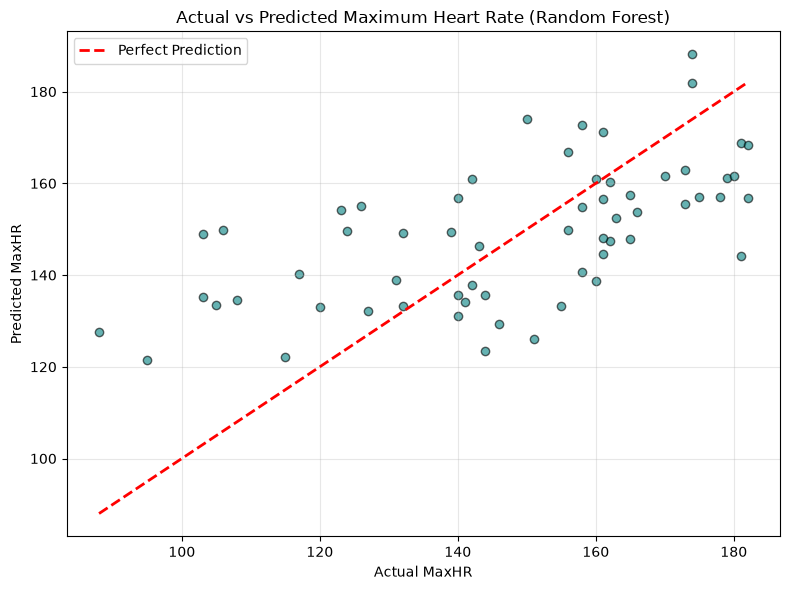

In [11]:
print("\n" + "="*80)
print("PART 8: VISUALIZING ACTUAL vs PREDICTED VALUES")
print("="*80)

plt.figure(figsize=(8, 6))
plt.scatter(y_test, y_pred, alpha=0.6, edgecolors='k', color='teal')
plt.plot([y_test.min(), y_test.max()], [y_test.min(), y_test.max()], 'r--', lw=2, label='Perfect Prediction')
plt.xlabel('Actual MaxHR')
plt.ylabel('Predicted MaxHR')
plt.title('Actual vs Predicted Maximum Heart Rate (Random Forest)')
plt.legend()
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()


## **PART 9: SWAPPING ESTIMATORS (Demonstrating Pipeline Flexibility)**
*   **Modularity:** This part highlights the true power of the Scikit-Learn Pipeline architecture. Because the preprocessing steps are decoupled from the modeling step, we can swap out a complex, non-linear model (`RandomForestRegressor`) for a simple, linear model (`LinearRegression`) in just one line of code.
*   **Apples-to-Apples Comparison:** Because the exact same preprocessing (imputation, scaling, encoding) is applied seamlessly behind the scenes, we can confidently compare the R² scores of the two models to see which algorithm handles the Heart Disease data better. (In this case, Random Forest's 0.3661 beat Linear Regression's 0.2826).

In [12]:
print("\n" + "="*80)
print("PART 9: SWAPPING ESTIMATORS (The Power of Pipelines)")
print("="*80)
print("Because we used a Pipeline, we can easily swap the algorithm without")
print("rewriting the preprocessing code. Let's test Linear Regression.")

# Create a new pipeline with Linear Regression
lr_pipeline = Pipeline(steps=[
    ('preprocessor', preprocessor),
    ('regressor', LinearRegression())
])

lr_pipeline.fit(X_train, y_train)
y_pred_lr = lr_pipeline.predict(X_test)

print(f"Linear Regression R² on Test Set: {r2_score(y_test, y_pred_lr):.4f}")
print("(Notice how the exact same preprocessing was applied seamlessly!)")

print("\n" + "="*80)
print("SESSION 4 COMPLETE!")
print("="*80)


PART 9: SWAPPING ESTIMATORS (The Power of Pipelines)
Because we used a Pipeline, we can easily swap the algorithm without
rewriting the preprocessing code. Let's test Linear Regression.
Linear Regression R² on Test Set: 0.2826
(Notice how the exact same preprocessing was applied seamlessly!)

SESSION 4 COMPLETE!
